Source data: [SIGNS dataset](https://drive.google.com/file/d/1ufiR6hUKhXoAyiBNsySPkUwlvE_wfEHC/view) (downloaded automatically below)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BetterED-Neoversity/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/blob/main/notebooks/Module_3_Lecture_5_Class.ipynb)

In [1]:
# !pip install opencv-python

In [2]:
import os
import random
from collections import defaultdict
from tqdm.auto import tqdm

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid

import cv2
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torch.nn.functional as F

from sklearn.metrics import balanced_accuracy_score

import warnings
# filter warnings
warnings.filterwarnings('ignore')

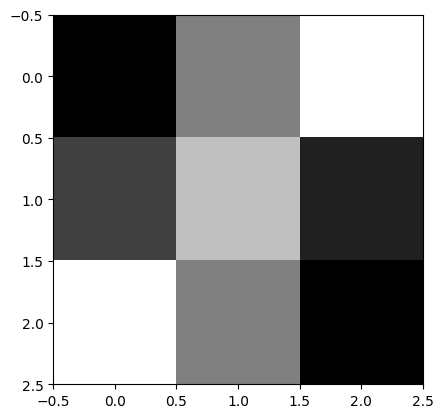

In [3]:
data = [[0, 128, 255], [64, 192, 32], [255, 128, 0]]
plt.imshow(data, cmap='gray')
plt.show()

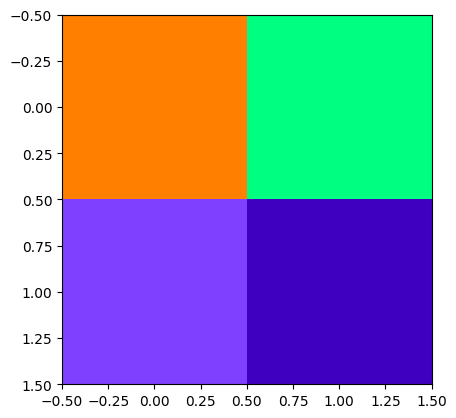

In [4]:
data = [[[255, 0], [128, 64]], [[128, 255], [64, 0]], [[0, 128], [255, 192]]]
data = np.moveaxis(data, 0, -1)
plt.imshow(data)
plt.show()

In [5]:
# Download the SIGNS dataset (~1.1 GB) from Google Drive and unpack it once.
# gdown is preinstalled in Colab; locally run `pip install gdown` first.
# If Google Drive refuses the download (quota), download the archive manually
# from the link above and unpack `train_signs` and `test_signs` to the same folder.
import zipfile
import gdown

SIGNS_DIR = 'data/Module_3_Lecture_1_SIGNS_dataset'

if not os.path.isdir(os.path.join(SIGNS_DIR, 'train_signs')):
    os.makedirs(SIGNS_DIR, exist_ok=True)
    zip_path = gdown.download(id='1ufiR6hUKhXoAyiBNsySPkUwlvE_wfEHC',
                              output='data/SIGNS_dataset.zip', quiet=True)
    with zipfile.ZipFile(zip_path) as zf:
        for member in zf.infolist():
            # keep only the images: skip macOS service files (__MACOSX, .DS_Store)
            name = member.filename
            if name.startswith('SIGNS dataset/') and name.endswith('.jpg'):
                member.filename = name[len('SIGNS dataset/'):]
                zf.extract(member, SIGNS_DIR)
    os.remove(zip_path)

print(os.listdir(SIGNS_DIR))

['train_signs', 'test_signs']


In [6]:
data_path = 'data/Module_3_Lecture_1_SIGNS_dataset/'
splits = ['train', 'test']

1080 images in train
Number of examples for class 0: 180


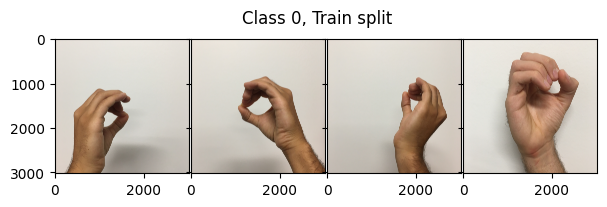

Number of examples for class 1: 180


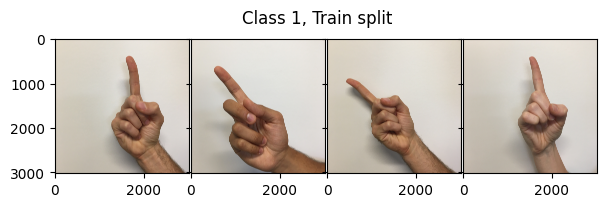

Number of examples for class 2: 180


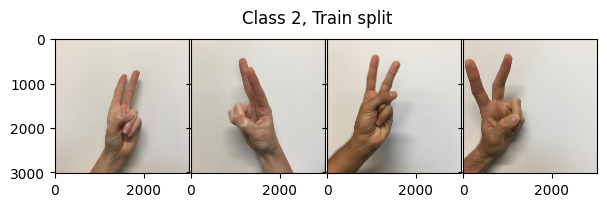

Number of examples for class 3: 180


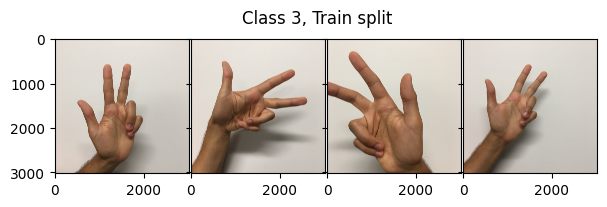

Number of examples for class 4: 180


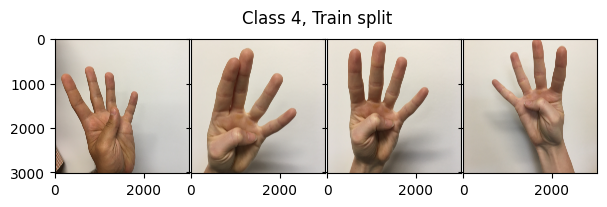

Number of examples for class 5: 180


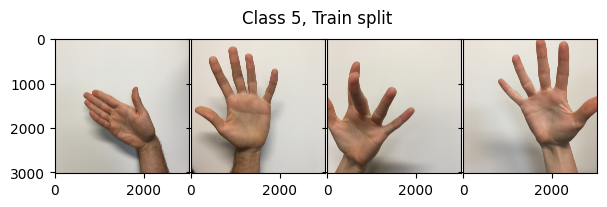

120 images in test
Number of examples for class 0: 20
Number of examples for class 1: 20
Number of examples for class 2: 20
Number of examples for class 3: 20
Number of examples for class 4: 20
Number of examples for class 5: 20


In [7]:
# Display images examples

# iterate over train and test folders
for s in splits:
    # list files in the folder with the jpg extension
    files = [f for f in os.listdir(f"{data_path}{s}_signs") if f.endswith('.jpg')]
    print(f'{len(files)} images in {s}')

    # for each image, create a list of the type [class, filename]
    files = [f.split('_', 1) for f in files]

    # group the data by class
    files_by_sign = defaultdict(list)
    for k, v in files:
        files_by_sign[k].append(v)

    # take random 4 images of each class
    for k, v in sorted(files_by_sign.items()):
        print(f'Number of examples for class {k}:', len(v))

        # display several examples of images from the training sample
        if s == 'train':
            random.seed(42)

            imgs_path = random.sample(v, 4)
            imgs_path = [os.path.join(data_path, f'{s}_signs/{k}_{p}') for p in imgs_path]

            # read the image using the opencv library
            imgs = [cv2.imread(p) for p in imgs_path]
            # matplotlib expects img in RGB format but OpenCV provides it in BGR
            # transform the BGR image into RGB
            imgs = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in imgs]

            # create a figure for display
            fig = plt.figure(figsize=(7, 2))
            grid = ImageGrid(
                fig, 111,
                nrows_ncols=(1, 4)
            )
            # display the image
            for ax, img in zip(grid, imgs):
                ax.imshow(img)

            fig.suptitle(f'Class {k}, {s.capitalize()} split')
            plt.show()

In [8]:
# Image shape, (h, w, dim)
img.shape

(3024, 3024, 3)

Convolution layer

In [9]:
input = torch.randn(20, 16, 50, 100) # batch_size, in_channels, h, w

In [10]:
# With square kernels and equal stride
m = nn.Conv2d(16, 33, 3, stride=2)
output = m(input)
output.shape

torch.Size([20, 33, 24, 49])

In [11]:
# non-square kernels and unequal stride and with padding
m = nn.Conv2d(16, 33, (3, 5), stride=(2, 1), padding=(4, 2))
output = m(input)
output.shape

torch.Size([20, 33, 28, 100])

Pooling layer

In [12]:
input = torch.randn(20, 16, 50, 100) # batch_size, in_channels, h, w

In [13]:
# pool of square window of kernel_size=3, stride=2
m = nn.MaxPool2d(3, stride=2)
output = m(input)
output.shape

torch.Size([20, 16, 24, 49])

In [14]:
# pool of non-square window
m = nn.MaxPool2d((3, 2), stride=(2, 1))
output = m(input)
output.shape

torch.Size([20, 16, 24, 99])

Classification layers

## Augmentations

**Data Augmentation** is a technique used to artificially increase dataset size. Take a sample from the dataset, modify it somehow, add it to the original dataset — and now your dataset is one sample larger.

In [15]:
from PIL import Image

import torchvision.transforms as T

In [16]:
orig_img = Image.fromarray(img)

In [17]:
def plot_examples(transformed_imgs:list, col_titles:list, cmap=None):
    
    n_cols = len(transformed_imgs) +1
    fig_size_x = 3 + len(transformed_imgs) * 1.5
    fig, axs = plt.subplots(1, n_cols, figsize=(fig_size_x,2))
    
    axs[0].imshow(orig_img)
    axs[0].set_title('original image')
    
    for i in range(len(transformed_imgs)):
        axs[i+1].imshow(transformed_imgs[i], cmap=cmap)
        axs[i+1].set_title(col_titles[i])
    
    plt.tight_layout()
    plt.show()

**Resize**

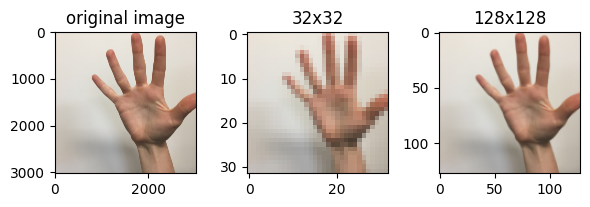

In [18]:
resized_imgs = [T.Resize(size=size)(orig_img) for size in [32,128]]

plot_examples(resized_imgs, ['32x32', '128x128'])

**Gray Scale**

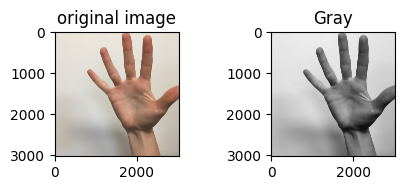

In [19]:
gray_img = T.Grayscale()(orig_img)

plot_examples([gray_img], ["Gray"], 'gray')

**Normalize**<br>
The normalization can constitute an effective way to speed up the computations in the model based on neural network architecture and learn faster. There are two steps to normalize the images:

* we subtract the channel mean from each input channel
* later, we divide it by the channel standard deviation.


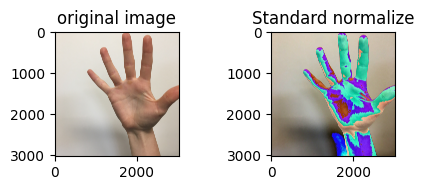

In [20]:
normalized_img = T.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))(T.ToTensor()(orig_img)) 
normalized_img = [T.ToPILImage()(normalized_img)]

plot_examples(normalized_img, ["Standard normalize"])

**Random Rotation**

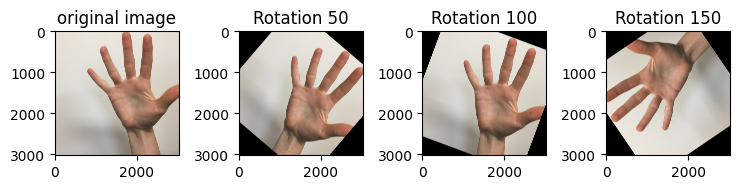

In [21]:
rotated_imgs = [T.RandomRotation(degrees=d)(orig_img) for d in range(50,151,50)]
plot_examples(rotated_imgs, ["Rotation 50","Rotation 100","Rotation 150"])

**Center Crop**

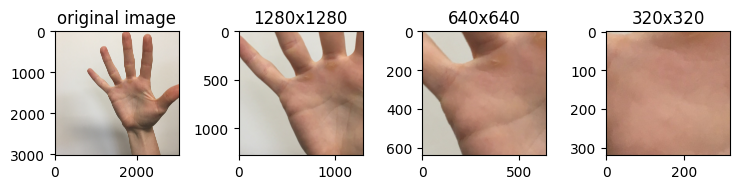

In [22]:
center_crops = [T.CenterCrop(size=size)(orig_img) for size in (1280,640, 320)]
plot_examples(center_crops,['1280x1280','640x640','320x320'])

**Random Crop**

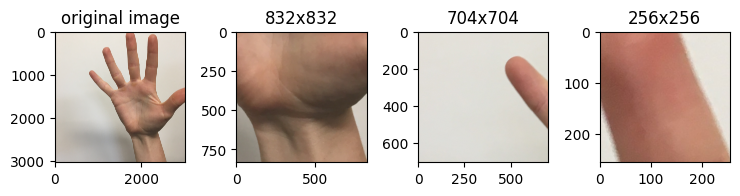

In [23]:
random_crops = [T.RandomCrop(size=size)(orig_img) for size in (832,704, 256)]
plot_examples(random_crops,['832x832','704x704','256x256'])

**Gaussian Blur**<br>

We apply a Gaussian blur transform to the image using a Gaussian kernel. This method can be helpful in making the image less clear and distinct and, then, this resulting image is fed into a neural network, which becomes more robust in learning patterns of the samples.

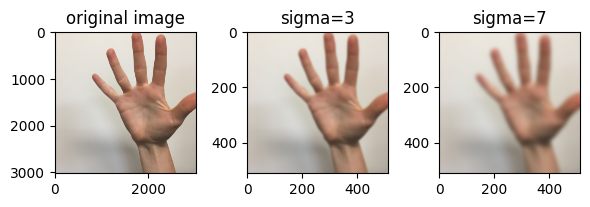

In [24]:
downsized_img = T.Resize(size=512)(orig_img)
blurred_imgs = [T.GaussianBlur(kernel_size=(51, 91), sigma=sigma)(downsized_img) for sigma in (3,7)]
plot_examples(blurred_imgs, ['sigma=3', 'sigma=7'])

**Gaussian Noise** <br>
The Gaussian Noise is a popular way to add noise to the whole dataset, forcing the model to learn the most important information contained in the data. It consists in injecting a Gaussian Noise matrix, which is a matrix of random values drawn from a Gaussian distribution. Later, we clip the samples between 0 and 1. The more the noise factor is higher, the more noisy the image is.

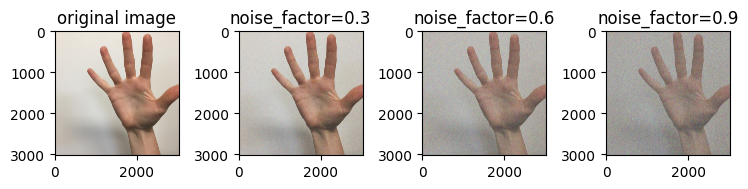

In [25]:
def add_noise(inputs,noise_factor=0.3):
    noisy = inputs+torch.randn_like(inputs) * noise_factor
    noisy = torch.clip(noisy,0.,1.)
    return noisy
    
noise_imgs = [add_noise(T.ToTensor()(orig_img),noise_factor) for noise_factor in (0.3,0.6,0.9)]
noise_imgs = [T.ToPILImage()(noise_img) for noise_img in noise_imgs]
plot_examples(noise_imgs, ["noise_factor=0.3","noise_factor=0.6","noise_factor=0.9"])

**Random Blocks**

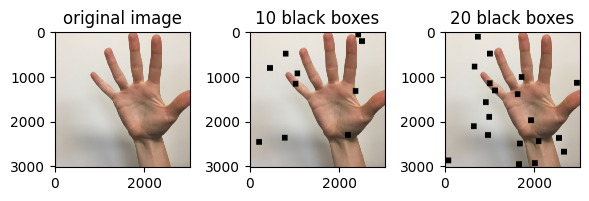

In [26]:
def add_random_boxes(img,n_k,size=32):
    h,w = size,size
    img = np.array(img)
    img_size = img.shape[1]
    boxes = []
    for k in range(n_k):
        y,x = np.random.randint(0,img_size-w,(2,))
        img[y:y+h,x:x+w] = 0
        boxes.append((x,y,h,w))
    img = Image.fromarray(img.astype('uint8'), 'RGB')
    return img

blocks_imgs = [add_random_boxes(orig_img,n_k=i, size=128) for i in (10,20)]
plot_examples(blocks_imgs, ["10 black boxes","20 black boxes"])

Usefull library: https://github.com/albumentations-team/albumentations

### Batch Normalization

In [27]:
# With Learnable Parameters
m = nn.BatchNorm1d(5) # num_features
input = torch.randn(4, 5)
# Without Learnable Parameters
m = nn.BatchNorm1d(5, affine=False) # no learnable parameters γ and β

output = m(input)

print('Input:\n', input, '\n\n', f'mean {input.mean()}, std {input.std()}', '\n')
print('Output:\n', output, '\n\n', f'mean {output.mean()}, std {output.std()}', '\n')

Input:
 tensor([[ 0.9833,  0.0065,  1.0080,  0.0897, -1.7328],
        [ 0.3235,  0.2794,  0.9933,  2.6639,  1.0218],
        [-1.3363,  1.5246,  0.9282, -0.5545, -1.8870],
        [ 0.8983,  1.1646, -0.5601,  1.5625,  0.2511]]) 

 mean 0.3813900947570801, std 1.1520179510116577 

Output:
 tensor([[ 0.8219, -1.1859,  0.6240, -0.6770, -0.9137],
        [ 0.1141, -0.7469,  0.6020,  1.3716,  1.2824],
        [-1.6666,  1.2559,  0.5043, -1.1897, -1.0366],
        [ 0.7306,  0.6769, -1.7303,  0.4951,  0.6679]]) 

 mean -2.9802322387695312e-08, std 1.0259709358215332 



## Baseline

In [28]:
class SIGNSDataset(Dataset):
    def __init__(self, data_dir, transform):
        # save file names
        self.filenames = os.listdir(data_dir)
        self.filenames = [os.path.join(data_dir, f) for f in self.filenames if f.endswith('.jpg')]
        # the first character of the file name contains the class label
        self.labels = [int(filename.split('/')[-1][0]) for filename in self.filenames]
        # save the transformations (augmentations) that we will apply to the images
        self.transform = transform

    def __len__(self):
        # returns the size of the dataset
        return len(self.filenames)

    def __getitem__(self, idx):
        # open the image, apply transformations and
        # return an image with a class label
        image = Image.open(self.filenames[idx])  # PIL image
        image = self.transform(image)
        return image, self.labels[idx]

In [29]:
train_transformer = T.Compose([
    T.Resize(64),              # resizing the image to 64x64
    T.RandomHorizontalFlip(),  # randomly flip image horizontally
    T.ToTensor()])             # transform it into a PyTorch Tensor

eval_transformer = T.Compose([
    T.Resize(64),
    T.ToTensor()])

In [30]:
train_dataset = SIGNSDataset(f'{data_path}train_signs/', train_transformer)
test_dataset = SIGNSDataset(f'{data_path}test_signs/', eval_transformer)

In [31]:
class BaselineModel(nn.Module):

    def __init__(self, ):
        super().__init__()
        self.num_channels = 32

        # convolution base
        self.conv1 = nn.Conv2d(3, self.num_channels, 3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(self.num_channels, self.num_channels*2, 3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(self.num_channels*2, self.num_channels*4, 3, stride=1, padding=1)

        # classification layers
        self.fc1 = nn.Linear(8*8*self.num_channels*4, self.num_channels*4)
        self.fc2 = nn.Linear(self.num_channels*4, 6)

    def forward(self, s):
        #                                                  -> batch_size x 3 x 64 x 64
        s = self.conv1(s)                                   # batch_size x num_channels x 64 x 64
        s = F.relu(F.max_pool2d(s, 2))                      # batch_size x num_channels x 32 x 32
        s = self.conv2(s)                                   # batch_size x num_channels*2 x 32 x 32
        s = F.relu(F.max_pool2d(s, 2))                      # batch_size x num_channels*2 x 16 x 16
        s = self.conv3(s)                                   # batch_size x num_channels*4 x 16 x 16
        s = F.relu(F.max_pool2d(s, 2))                      # batch_size x num_channels*4 x 8 x 8

        # flatten the output for each image
        s = s.view(-1, 8*8*self.num_channels*4)             # batch_size x 8*8*num_channels*4

        # apply 2 fully connected layers
        s = F.relu(self.fc1(s))                             # batch_size x self.num_channels*4
        s = self.fc2(s)                                     # batch_size x 6

        return F.log_softmax(s, dim=1)

In [32]:
cuda = torch.cuda.is_available()  

# Set the random seed for reproducible experiments
torch.manual_seed(42)
if cuda:
    torch.cuda.manual_seed(42)

# Specify a computing device
device = 'cuda' if cuda else None

In [33]:
train_dataloader = DataLoader(train_dataset,
                              batch_size=32, 
                              shuffle=True,
                              num_workers=4)

test_dataloader = DataLoader(test_dataset,
                             batch_size=32, 
                             shuffle=False,
                             num_workers=1)

In [34]:
# Define the model and optimizer
model = BaselineModel().to(device) 
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [35]:
model

BaselineModel(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=8192, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=6, bias=True)
)

In [36]:
# Define loss function
criterion = nn.CrossEntropyLoss().to(device)

# Train the model

train_losses = []
train_accs = []

test_losses = []
test_accs = []

num_epochs = 15

for epoch in tqdm(range(num_epochs)):
    
    # Train step
    
    model.train()
    
    train_epoch_loss = []
    train_epoch_acc = []
    
    for i, (train_batch, labels_batch) in tqdm(enumerate(train_dataloader)):
        if cuda:
            # non_blocking=True enables asynchronous data transfer to reduce runtime
            train_batch, labels_batch = train_batch.cuda(non_blocking=True), labels_batch.cuda(non_blocking=True)

        # compute model output and loss
        output_batch = model(train_batch)

        loss = criterion(output_batch, labels_batch)

        # clear previous gradients, compute gradients of all variables wrt loss
        optimizer.zero_grad()
        loss.backward()

        # performs updates using calculated gradients
        optimizer.step()
        
        batch_loss = loss.cpu().detach().numpy()
        batch_acc = balanced_accuracy_score(labels_batch.cpu().detach().numpy(),
                                            np.argmax(output_batch.cpu().detach().numpy(), axis=1))
        
        train_epoch_loss.append(batch_loss)
        train_epoch_acc.append(batch_acc)
        
    
    print(f'Train epoch [{epoch+1}/{num_epochs}], Loss: {np.mean(train_epoch_loss):.4f}, Acc: {np.mean(train_epoch_acc)}')
    train_accs.append(np.mean(train_epoch_acc))
    train_losses.append(np.mean(train_epoch_loss))
    
    # Eval step
    
    model.eval()
    
    test_epoch_loss = []
    test_epoch_acc = []
    
    with torch.no_grad():
        
        for i, (test_batch, labels_batch) in enumerate(test_dataloader):
            if cuda:
                test_batch, labels_batch = test_batch.cuda(non_blocking=True), labels_batch.cuda(non_blocking=True)

            # compute model output and loss
            output_batch = model(test_batch)

            loss = criterion(output_batch, labels_batch)

            batch_loss = loss.cpu().detach().numpy()
            batch_acc = balanced_accuracy_score(labels_batch.cpu().detach().numpy(),
                                                np.argmax(output_batch.cpu().detach().numpy(), axis=1))

            test_epoch_loss.append(batch_loss)
            test_epoch_acc.append(batch_acc)
    print(f'Test epoch [{epoch+1}/{num_epochs}], Loss: {np.mean(test_epoch_loss):.4f}, Acc: {np.mean(test_epoch_acc)}')        
    test_accs.append(np.mean(test_epoch_acc))
    test_losses.append(np.mean(test_epoch_loss))

100%|██████████| 15/15 [04:16<00:00, 17.48s/it]

 34/? [00:11<00:00,  2.96it/s]

Train epoch [1/15], Loss: 1.7932, Acc: 0.17494553376906322
Test epoch [1/15], Loss: 1.7791, Acc: 0.16666666666666666


 34/? [00:11<00:00,  2.77it/s]

Train epoch [2/15], Loss: 1.6118, Acc: 0.3154839713663243
Test epoch [2/15], Loss: 1.4402, Acc: 0.3952711640211641


 34/? [00:11<00:00,  2.71it/s]

... (21 outputs left out)

 34/? [00:12<00:00,  2.90it/s]

Train epoch [14/15], Loss: 0.1631, Acc: 0.943997043261749
Test epoch [14/15], Loss: 0.2460, Acc: 0.9174933862433863


 34/? [00:12<00:00,  2.91it/s]

Train epoch [15/15], Loss: 0.1399, Acc: 0.9475214328155505
Test epoch [15/15], Loss: 0.2013, Acc: 0.916848544973545


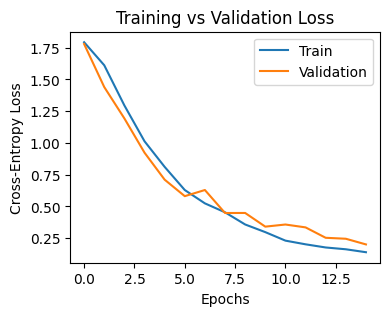

In [37]:
plt.figure(figsize=(4, 3))
plt.plot(train_losses, label='Train')
plt.plot(test_losses, label='Validation')
plt.legend(loc='best')
plt.xlabel('Epochs')
plt.ylabel('Cross-Entropy Loss')
plt.title('Training vs Validation Loss')
plt.show()

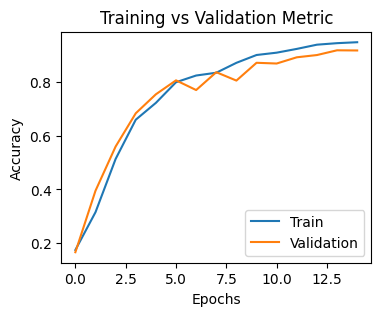

In [38]:
plt.figure(figsize=(4, 3))
plt.plot(train_accs, label='Train')
plt.plot(test_accs, label='Validation')
plt.legend(loc='best')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Metric')
plt.show()